<a href="https://colab.research.google.com/github/harsha-vardhann-reddy/Deep-Learning-Session/blob/main/Week_6_DLAC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import urllib.request
import zipfile

# Re-create directory structure
annotations_dir = "./coco_week5_audit/annotations"
os.makedirs(annotations_dir, exist_ok=True)

ann_json_path = os.path.join(annotations_dir, "instances_val2017.json")

if not os.path.exists(ann_json_path):
    print("Downloading COCO val2017 annotations...")
    url = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
    zip_path = "./annotations_trainval2017.zip"
    urllib.request.urlretrieve(url, zip_path)

    print("Extracting instances_val2017.json...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        # Extract only the required validation annotations file
        zip_ref.extract("annotations/instances_val2017.json", path="./coco_week5_audit_temp")

    # Move to the correct final path
    os.rename("./coco_week5_audit_temp/annotations/instances_val2017.json", ann_json_path)

    # Clean up temporary files
    if os.path.exists(zip_path):
        os.remove(zip_path)
    import shutil
    if os.path.exists("./coco_week5_audit_temp"):
        shutil.rmtree("./coco_week5_audit_temp")
    print("Successfully downloaded and placed instances_val2017.json!")
else:
    print("instances_val2017.json already exists!")

Extracting instances_val2017.json...
Successfully downloaded and placed instances_val2017.json!


In [2]:
import os
import json
import math
import shutil
import urllib.request
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

plt.rcParams["figure.dpi"] = 120
print("Week 6 environment initialized.")

Week 6 environment initialized.


In [3]:
week5_dir = "./coco_week5_audit"
week6_dir = "./coco_week6_prep"
os.makedirs(week6_dir, exist_ok=True)

ann_json_path = os.path.join(week5_dir, "annotations", "instances_val2017.json")
assert os.path.exists(ann_json_path), "Run Week 5 Cell 2 first so instances_val2017.json exists!"

with open(ann_json_path, "r", encoding="utf-8") as f:
    coco_data = json.load(f)

images = coco_data["images"]
annotations = coco_data["annotations"]
categories = coco_data["categories"]

cat_id_to_name = {c["id"]: c["name"] for c in categories}
img_id_to_info = {img["id"]: img for img in images}

print(f"Loaded {len(images):,} images, {len(annotations):,} annotations, {len(categories)} categories.")

Loaded 5,000 images, 36,781 annotations, 80 categories.


In [4]:
TARGET_CLASSES = [
    "person", "bicycle", "car", "motorcycle",
    "bus", "truck", "traffic light", "stop sign"
]

target_cat_ids = {c["id"] for c in categories if c["name"] in TARGET_CLASSES}
traffic_anns = [ann for ann in annotations if ann["category_id"] in target_cat_ids]
traffic_img_ids = sorted({ann["image_id"] for ann in traffic_anns})

print(f"Target Traffic Classes ({len(TARGET_CLASSES)}): {TARGET_CLASSES}")
print(f"Filtered Annotations : {len(traffic_anns):,} / {len(annotations):,} ({len(traffic_anns)/len(annotations)*100:.1f}%)")
print(f"Images w/ Traffic Obj: {len(traffic_img_ids):,} / {len(images):,} ({len(traffic_img_ids)/len(images)*100:.1f}%)")

Target Traffic Classes (8): ['person', 'bicycle', 'car', 'motorcycle', 'bus', 'truck', 'traffic light', 'stop sign']
Filtered Annotations : 15,035 / 36,781 (40.9%)
Images w/ Traffic Obj: 3,028 / 5,000 (60.6%)


=== Traffic-Subset Class Counts ===


,instance_count
class_name,
person,11004
bicycle,316
car,1932
motorcycle,371
bus,285
truck,415
traffic light,637
stop sign,75


Max-to-Min Class Imbalance Ratio: 146.7x (person vs stop sign)


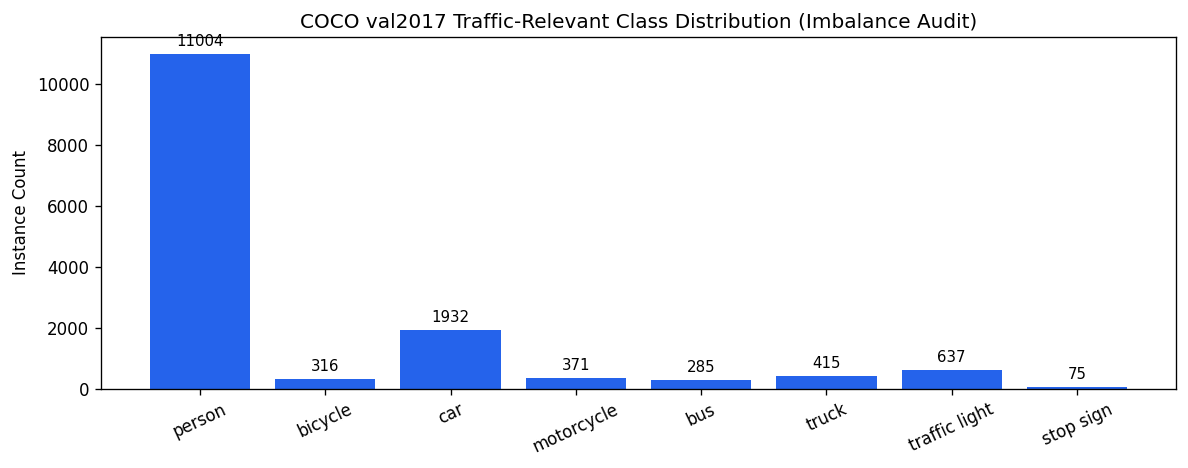

In [5]:
traffic_df = pd.DataFrame(traffic_anns)
traffic_df["class_name"] = traffic_df["category_id"].map(cat_id_to_name)

class_counts = traffic_df["class_name"].value_counts().reindex(TARGET_CLASSES, fill_value=0)
imbalance_ratio = class_counts.max() / max(class_counts.min(), 1)

print("=== Traffic-Subset Class Counts ===")
display(class_counts.to_frame(name="instance_count"))
print(f"Max-to-Min Class Imbalance Ratio: {imbalance_ratio:.1f}x ({class_counts.idxmax()} vs {class_counts.idxmin()})")

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(class_counts.index, class_counts.values, color="#2563EB")
ax.set_title("COCO val2017 Traffic-Relevant Class Distribution (Imbalance Audit)")
ax.set_ylabel("Instance Count")
ax.bar_label(bars, padding=3, fontsize=9)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [6]:
objs_per_img = traffic_df.groupby("image_id").size()

print("=== Traffic Objects per Image Statistics ===")
print(objs_per_img.describe().round(2))

# Build class co-occurrence matrix across images
img_classes = traffic_df.groupby("image_id")["class_name"].apply(set)
co_matrix = pd.DataFrame(0, index=TARGET_CLASSES, columns=TARGET_CLASSES)

for cls_set in img_classes:
    for c1 in cls_set:
        for c2 in cls_set:
            co_matrix.loc[c1, c2] += 1

print("\n=== Class Co-Occurrence Matrix (Images Containing Both Classes) ===")
display(co_matrix)

=== Traffic Objects per Image Statistics ===
count    3028.00
mean        4.97
std         5.23
min         1.00
25%         1.00
50%         3.00
75%         7.00
max        43.00
dtype: float64

=== Class Co-Occurrence Matrix (Images Containing Both Classes) ===


,person,bicycle,car,motorcycle,bus,truck,traffic light,stop sign
person,2693,122,359,128,143,159,113,20
bicycle,122,149,52,26,19,21,24,4
car,359,52,535,59,102,152,117,30
motorcycle,128,26,59,159,20,31,15,2
bus,143,19,102,20,189,46,35,5
truck,159,21,152,31,46,250,46,8
traffic light,113,24,117,15,35,46,191,9
stop sign,20,4,30,2,5,8,9,69


In [7]:
# Standard MS COCO scale thresholds (based on segmentation/bbox pixel area):
# Small: area < 32^2 (1,024 px) | Medium: 32^2 <= area < 96^2 (9,216 px) | Large: area >= 96^2
def classify_coco_scale(area):
    if area < 32 ** 2:
        return "Small (<32x32)"
    elif area < 96 ** 2:
        return "Medium (32x32 to 96x96)"
    else:
        return "Large (>=96x96)"

traffic_df["scale_bucket"] = traffic_df["area"].apply(classify_coco_scale)
scale_breakdown = pd.crosstab(traffic_df["class_name"], traffic_df["scale_bucket"])[
    ["Small (<32x32)", "Medium (32x32 to 96x96)", "Large (>=96x96)"]
]

print("=== Object Scale Distribution by Class ===")
display(scale_breakdown)

=== Object Scale Distribution by Class ===


scale_bucket,Small (<32x32),Medium (32x32 to 96x96),Large (>=96x96)
class_name,,,
bicycle,141,125,50
bus,36,84,165
car,1194,555,183
motorcycle,91,140,140
person,4336,3800,2868
stop sign,27,21,27
traffic light,518,100,19
truck,117,165,133


In [8]:
widths = traffic_df["bbox"].apply(lambda b: b[2])
heights = traffic_df["bbox"].apply(lambda b: b[3])
traffic_df["bbox_w"] = widths
traffic_df["bbox_h"] = heights
traffic_df["aspect_ratio"] = (widths / heights.replace(0, np.nan)).round(2)

aspect_summary = traffic_df.groupby("class_name")["aspect_ratio"].agg(
    count="count", median_ar="median", p10_ar=lambda s: np.percentile(s.dropna(), 10), p90_ar=lambda s: np.percentile(s.dropna(), 90)
).round(2)

print("=== Bounding-Box Aspect Ratio (Width / Height) by Class ===")
display(aspect_summary)

=== Bounding-Box Aspect Ratio (Width / Height) by Class ===


,count,median_ar,p10_ar,p90_ar
class_name,,,,
bicycle,316,0.91,0.43,1.98
bus,285,1.38,0.72,2.78
car,1932,1.41,0.72,2.79
motorcycle,371,1.01,0.54,1.92
person,11004,0.56,0.30,1.10
stop sign,75,0.96,0.59,1.07
traffic light,637,0.53,0.35,1.10
truck,415,1.46,0.78,2.51


In [9]:
traffic_imgs_df = pd.DataFrame([img_id_to_info[iid] for iid in traffic_img_ids])
traffic_imgs_df["orientation"] = np.where(
    traffic_imgs_df["width"] > traffic_imgs_df["height"], "Landscape",
    np.where(traffic_imgs_df["width"] < traffic_imgs_df["height"], "Portrait", "Square")
)

print("=== Image Orientation Breakdown ===")
print(traffic_imgs_df["orientation"].value_counts())

print("\nTop 5 Most Common Image Resolutions:")
print(traffic_imgs_df.apply(lambda r: f"{r['width']}x{r['height']}", axis=1).value_counts().head(5))

=== Image Orientation Breakdown ===
orientation
Landscape    2181
Portrait      757
Square         90
Name: count, dtype: int64

Top 5 Most Common Image Resolutions:
640x480    603
640x427    384
480x640    179
500x375    143
640x426    136
Name: count, dtype: int64


In [10]:
# Map non-contiguous COCO category IDs -> contiguous 0..N-1 indices required by YOLO/PyTorch detectors
sorted_target_cats = sorted([c for c in categories if c["name"] in TARGET_CLASSES], key=lambda x: x["id"])
coco_id_to_contiguous = {c["id"]: idx for idx, c in enumerate(sorted_target_cats)}
contiguous_to_name = {idx: c["name"] for idx, c in enumerate(sorted_target_cats)}

# Select a clean 50-image mini-benchmark subset (reproducible seed)
rng = np.random.default_rng(seed=42)
subset_img_ids = sorted(rng.choice(traffic_img_ids, size=50, replace=False).tolist())
split_idx = int(0.8 * len(subset_img_ids))

train_ids = subset_img_ids[:split_idx]
val_ids = subset_img_ids[split_idx:]

print("Contiguous Class Mapping (Detector Ready):")
for k, v in contiguous_to_name.items():
    print(f"  Class {k}: {v}")
print(f"\nMini-Benchmark Split -> Train: {len(train_ids)} images | Val: {len(val_ids)} images")

Contiguous Class Mapping (Detector Ready):
  Class 0: person
  Class 1: bicycle
  Class 2: car
  Class 3: motorcycle
  Class 4: bus
  Class 5: truck
  Class 6: traffic light
  Class 7: stop sign

Mini-Benchmark Split -> Train: 40 images | Val: 10 images


In [11]:
def coco_to_yolo_bbox(bbox, img_w, img_h):
    """Convert COCO [x_min, y_min, w, h] in pixels to normalized YOLO [x_center, y_center, w, h] in [0, 1]."""
    x_min, y_min, w, h = bbox
    x_center = (x_min + w / 2.0) / img_w
    y_center = (y_min + h / 2.0) / img_h
    norm_w = w / img_w
    norm_h = h / img_h
    # Clamp strictly to [0.0, 1.0] to prevent boundary overflow
    return [
        round(min(max(x_center, 0.0), 1.0), 6),
        round(min(max(y_center, 0.0), 1.0), 6),
        round(min(max(norm_w, 0.0), 1.0), 6),
        round(min(max(norm_h, 0.0), 1.0), 6),
    ]

# Export YOLO label files and dataset.yaml for the 50-image subset
for split_name, id_list in [("train", train_ids), ("val", val_ids)]:
    lbl_dir = os.path.join(week6_dir, "labels", split_name)
    os.makedirs(lbl_dir, exist_ok=True)
    for img_id in id_list:
        info = img_id_to_info[img_id]
        stem = os.path.splitext(info["file_name"])[0]
        anns = [a for a in traffic_anns if a["image_id"] == img_id and a["iscrowd"] == 0]
        lines = []
        for a in anns:
            cls_idx = coco_id_to_contiguous[a["category_id"]]
            cx, cy, nw, nh = coco_to_yolo_bbox(a["bbox"], info["width"], info["height"])
            lines.append(f"{cls_idx} {cx} {cy} {nw} {nh}")
        with open(os.path.join(lbl_dir, f"{stem}.txt"), "w", encoding="utf-8") as out_f:
            out_f.write("\n".join(lines))

yaml_path = os.path.join(week6_dir, "coco_traffic_subset.yaml")
with open(yaml_path, "w", encoding="utf-8") as yf:
    yf.write(f"path: {os.path.abspath(week6_dir)}\ntrain: images/train\nval: images/val\nnames:\n")
    for idx, name in contiguous_to_name.items():
        yf.write(f"  {idx}: {name}\n")

print(f"Exported normalized YOLO labels and config to: {yaml_path}")

Exported normalized YOLO labels and config to: ./coco_week6_prep/coco_traffic_subset.yaml


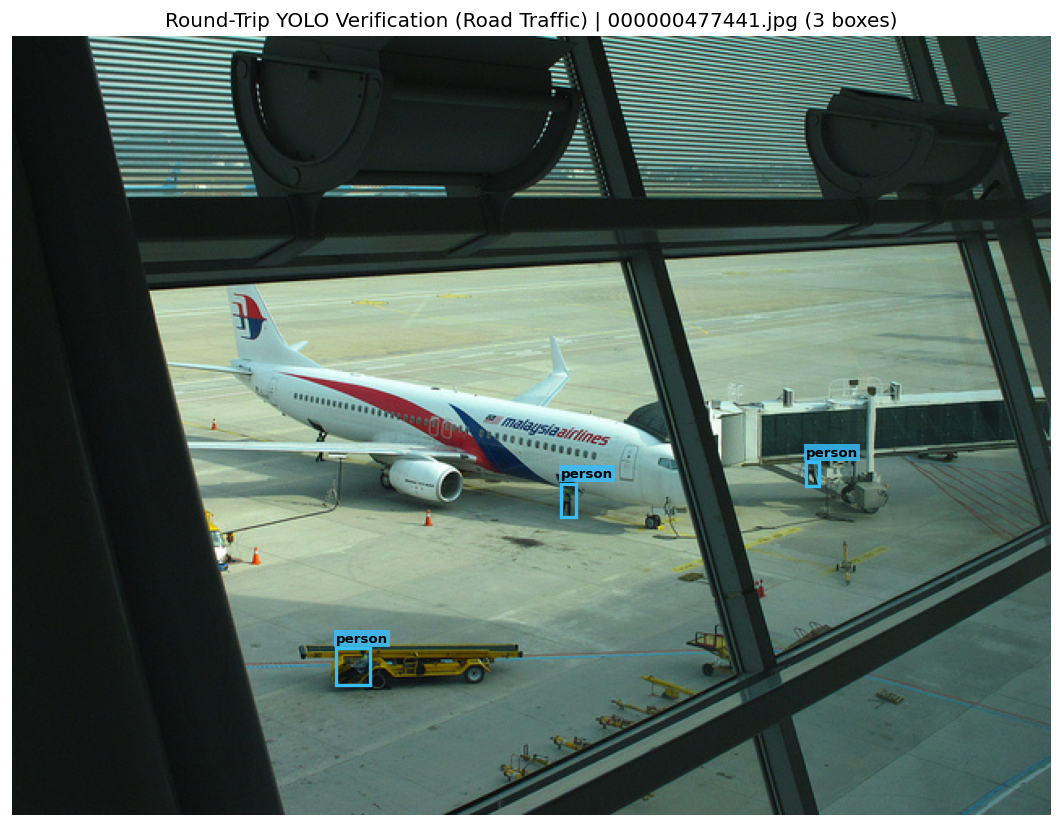

In [22]:
import urllib.request
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import os

# Force using the road traffic scene (000000477441.jpg)
sample_val_id = 477441

sample_info = img_id_to_info[sample_val_id]
sample_stem = os.path.splitext(sample_info["file_name"])[0]
sample_txt = os.path.join(week6_dir, "labels", "val", f"{sample_stem}.txt")

# Download the traffic sample image to verify reconstructed boxes visually
sample_img_path = os.path.join(week6_dir, sample_info["file_name"])
if not os.path.exists(sample_img_path):
    print(f"Downloading traffic scene: {sample_info['file_name']}...")
    urllib.request.urlretrieve(sample_info["coco_url"], sample_img_path)

with open(sample_txt, "r", encoding="utf-8") as f:
    yolo_lines = [line.strip().split() for line in f if line.strip()]

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(Image.open(sample_img_path).convert("RGB"))
ax.set_title(f"Round-Trip YOLO Verification (Road Traffic) | {sample_info['file_name']} ({len(yolo_lines)} boxes)")
ax.axis("off")

W, H = sample_info["width"], sample_info["height"]
for parts in yolo_lines:
    cls_idx = int(parts[0])
    cx, cy, nw, nh = map(float, parts[1:])
    # Reconstruct pixel coordinates from normalized YOLO format
    bw, bh = nw * W, nh * H
    xmin, ymin = (cx * W) - bw / 2.0, (cy * H) - bh / 2.0

    rect = patches.Rectangle((xmin, ymin), bw, bh, linewidth=2, edgecolor="#38BDF8", facecolor="none")
    ax.add_patch(rect)
    ax.text(xmin, max(ymin - 4, 0), contiguous_to_name[cls_idx], color="black", fontsize=8,
            fontweight="bold", bbox=dict(facecolor="#38BDF8", alpha=0.85, pad=1.2, edgecolor="none"))

plt.tight_layout()
plt.show()

In [13]:
filtered_coco_json = {
    "info": {"description": "COCO val2017 Traffic-Relevant Subset (Week 6 DLAC Prep)"},
    "categories": sorted_target_cats,
    "images": [img_id_to_info[iid] for iid in traffic_img_ids],
    "annotations": [a for a in traffic_anns if a["iscrowd"] == 0]
}

filtered_json_path = os.path.join(week6_dir, "instances_traffic_val2017.json")
with open(filtered_json_path, "w", encoding="utf-8") as jf:
    json.dump(filtered_coco_json, jf)

print(f"Saved filtered COCO subset JSON: {filtered_json_path}")
print(f"Clean non-crowd annotations saved: {len(filtered_coco_json['annotations']):,}")

Saved filtered COCO subset JSON: ./coco_week6_prep/instances_traffic_val2017.json
Clean non-crowd annotations saved: 14,782


In [14]:
small_counts = scale_breakdown["Small (<32x32)"]
total_per_class = scale_breakdown.sum(axis=1)
small_pct = (small_counts / total_per_class * 100).round(1)

risk_df = pd.DataFrame({
    "total_instances": total_per_class,
    "small_instances": small_counts,
    "small_pct": small_pct
}).sort_values("small_pct", ascending=False)

print("=== Small-Object (<32x32 px) Risk Ranking ===")
display(risk_df)

=== Small-Object (<32x32 px) Risk Ranking ===


,total_instances,small_instances,small_pct
class_name,,,
traffic light,637,518,81.3
car,1932,1194,61.8
bicycle,316,141,44.6
person,11004,4336,39.4
stop sign,75,27,36.0
truck,415,117,28.2
motorcycle,371,91,24.5
bus,285,36,12.6


In [15]:
adaptation_notes = [
    ("Class Taxonomy Gap", "COCO lacks auto-rickshaws, e-rickshaws, tempos, and stray cattle; must append custom classes when fine-tuning on Indian datasets (e.g., IDD)."),
    ("Occlusion & Crowd Density", "Indian intersections exhibit higher bounding-box overlap than COCO's median object density; lower NMS IoU thresholds or Soft-NMS should be evaluated."),
    ("Small Distant Signals", f"Traffic lights have {small_pct.get('traffic light', 0)}% small (<32x32 px) instances in COCO; requires higher input resolution (e.g., 1280px) or P2 detection heads.")
]

print("=== Week 6 Modeling & Domain Transfer Takeaways ===")
for title, detail in adaptation_notes:
    print(f"- {title}: {detail}")

=== Week 6 Modeling & Domain Transfer Takeaways ===
- Class Taxonomy Gap: COCO lacks auto-rickshaws, e-rickshaws, tempos, and stray cattle; must append custom classes when fine-tuning on Indian datasets (e.g., IDD).
- Occlusion & Crowd Density: Indian intersections exhibit higher bounding-box overlap than COCO's median object density; lower NMS IoU thresholds or Soft-NMS should be evaluated.
- Small Distant Signals: Traffic lights have 81.3% small (<32x32 px) instances in COCO; requires higher input resolution (e.g., 1280px) or P2 detection heads.


In [16]:
week6_report = f"""
====================================================================
DLAC HANDOUT - WEEK 6 EDA & PREPROCESSING SUMMARY
====================================================================
1. Traffic Subset Scope  : {len(TARGET_CLASSES)} classes across {len(traffic_img_ids):,} images ({len(traffic_anns):,} instances)
2. Class Imbalance       : {imbalance_ratio:.1f}x skew ({class_counts.idxmax()}={class_counts.max():,} vs {class_counts.idxmin()}={class_counts.min():,})
3. Small-Object Hotspot  : '{risk_df.index[0]}' has {risk_df['small_pct'].iloc[0]}% small (<32x32 px) boxes
4. Label Standardization : Remapped non-contiguous COCO IDs to 0..{len(TARGET_CLASSES)-1} contiguous indices
5. Format Conversion     : Exported & round-trip verified normalized YOLO [cx, cy, w, h] labels
6. Filtered COCO Export  : {filtered_json_path}
7. Domain Boundary       : Represents COCO baseline traffic classes only; ready for transfer
                           learning onto Indian traffic datasets in subsequent weeks.
====================================================================
"""
print(week6_report)


DLAC HANDOUT - WEEK 6 EDA & PREPROCESSING SUMMARY
1. Traffic Subset Scope  : 8 classes across 3,028 images (15,035 instances)
2. Class Imbalance       : 146.7x skew (person=11,004 vs stop sign=75)
3. Small-Object Hotspot  : 'traffic light' has 81.3% small (<32x32 px) boxes
4. Label Standardization : Remapped non-contiguous COCO IDs to 0..7 contiguous indices
5. Format Conversion     : Exported & round-trip verified normalized YOLO [cx, cy, w, h] labels
6. Filtered COCO Export  : ./coco_week6_prep/instances_traffic_val2017.json
7. Domain Boundary       : Represents COCO baseline traffic classes only; ready for transfer
                           learning onto Indian traffic datasets in subsequent weeks.

